# Assignment 10: Adaptive Median Filtering and Otsu's Thresholding

## Objective
1. Implement Adaptive Median Filtering to remove noise from an image.
2. Compare Median Filter and Adaptive Median Filter using PSNR values.
3. Apply Otsu's Global Thresholding for image segmentation.

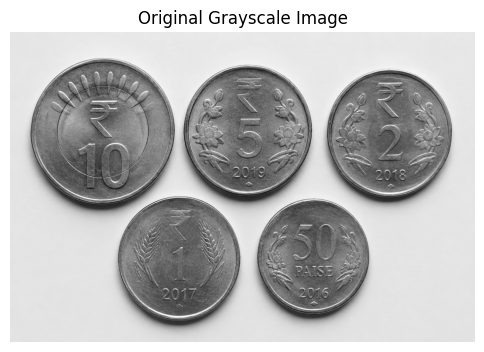

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio

img = cv2.imread('/content/Indian Coins Collection Overhead.png', 0)

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

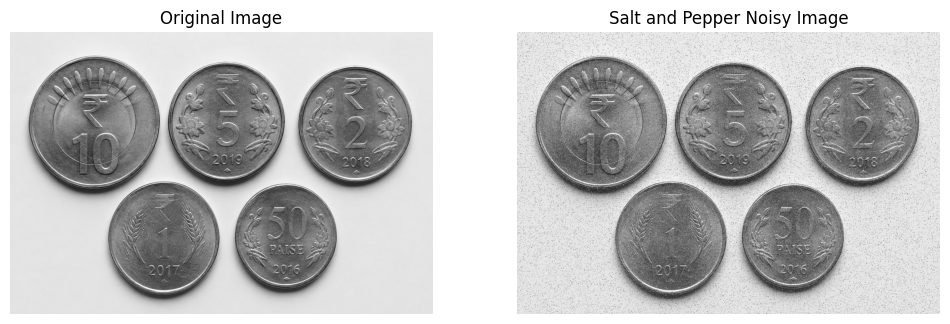

In [2]:
noisy = img.copy()

amount = 0.05
num_pixels = int(amount * img.size)

rows, cols = img.shape

for i in range(num_pixels):
    y = np.random.randint(0, rows)
    x = np.random.randint(0, cols)

    if np.random.rand() < 0.5:
        noisy[y, x] = 0
    else:
        noisy[y, x] = 255

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy, cmap='gray')
plt.title("Salt and Pepper Noisy Image")
plt.axis("off")

plt.show()

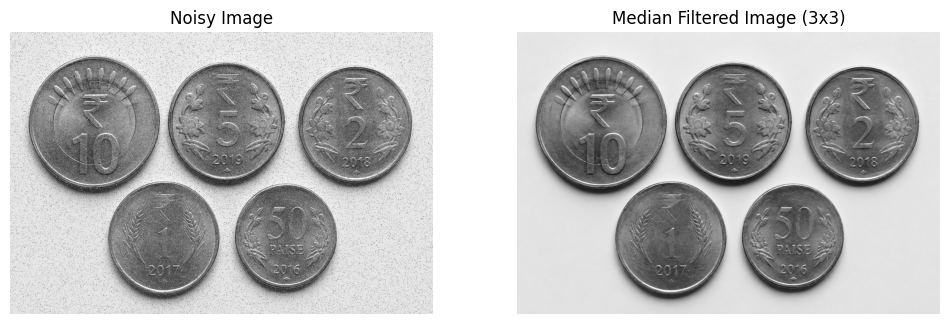

In [3]:
median_filtered = cv2.medianBlur(noisy, 3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noisy, cmap='gray')
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median_filtered, cmap='gray')
plt.title("Median Filtered Image (3x3)")
plt.axis("off")

plt.show()

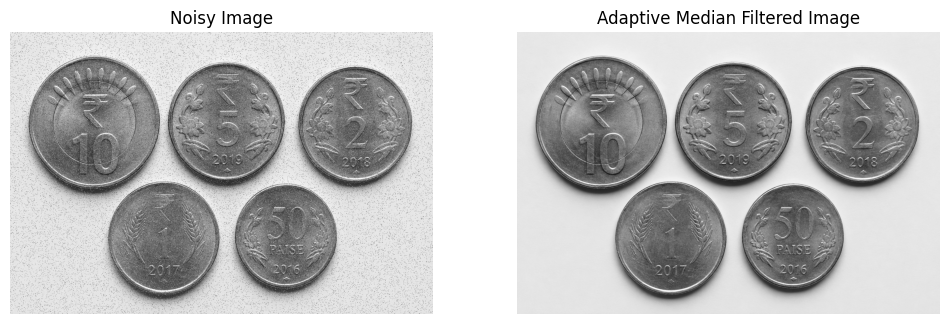

In [4]:
def adaptive_median(img, Smax=7):
    padded = cv2.copyMakeBorder(img, Smax//2, Smax//2, Smax//2, Smax//2, cv2.BORDER_REFLECT)
    output = img.copy()

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            size = 3

            while size <= Smax:
                x = i + Smax//2
                y = j + Smax//2

                window = padded[x-size//2:x+size//2+1, y-size//2:y+size//2+1]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = img[i, j]

                if zmin < zmed < zmax:
                    if zmin < zxy < zmax:
                        output[i, j] = zxy
                    else:
                        output[i, j] = zmed
                    break
                else:
                    size += 2

            if size > Smax:
                output[i, j] = zmed

    return output

adaptive_filtered = adaptive_median(noisy, 7)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noisy, cmap='gray')
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adaptive_filtered, cmap='gray')
plt.title("Adaptive Median Filtered Image")
plt.axis("off")

plt.show()

In [5]:
from skimage.metrics import peak_signal_noise_ratio

psnr_median = peak_signal_noise_ratio(img, median_filtered)
psnr_adaptive = peak_signal_noise_ratio(img, adaptive_filtered)

print("Median Filter PSNR:", psnr_median)
print("Adaptive Median Filter PSNR:", psnr_adaptive)

if psnr_adaptive > psnr_median:
    print("Adaptive Median Filter performs better.")
else:
    print("Median Filter performs better.")

Median Filter PSNR: 29.6330597838215
Adaptive Median Filter PSNR: 33.258586438302444
Adaptive Median Filter performs better.


## Part 2: Image Segmentation Using Otsu's Global Thresholding

### Objective
To segment a grayscale image into foreground and background using Otsu's automatic global thresholding method.

### Methodology
Otsu's method automatically calculates the best threshold value by separating image pixels into two classes based on their intensity.

Optimal Threshold Value: 170.0


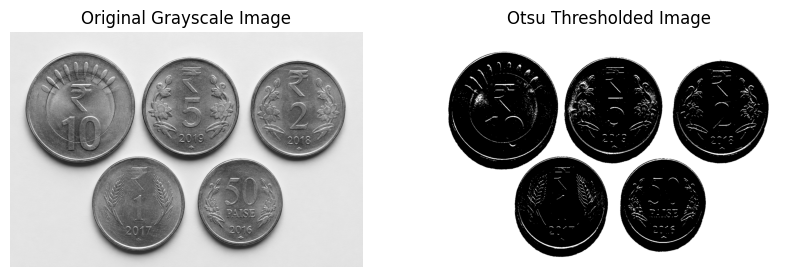

In [6]:
threshold_value, otsu_image = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Optimal Threshold Value:", threshold_value)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu_image, cmap='gray')
plt.title("Otsu Thresholded Image")
plt.axis("off")

plt.show()

## Conclusion

In this assignment, Adaptive Median Filtering and Otsu's Global Thresholding were successfully implemented using Python and OpenCV.

1. Adaptive Median Filter removed salt-and-pepper noise while preserving important image details.
2. Median Filter achieved a PSNR of 29.63 dB, while Adaptive Median Filter achieved 33.26 dB.
3. Adaptive Median Filter performed better because it produced a higher PSNR value.
4. Otsu's method automatically calculated the optimal threshold value as 170 and converted the grayscale image into a binary image.

Thus, both techniques were successfully used for image denoising and image segmentation.